# [GSE176389](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE176389)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-10-17
> - Modified: 2026-08-13

# 1. Experimental Design

> Tet1 regulates embryonic stem cell differentiation programs and development independent of its catalytic activity.
> - Stephanie Chrysanthou, Qin Tang, Joun Lee, Samuel J Taylor, Yilin Zhao, Ulrich Steidl, Deyou Zheng, Meelad M Dawlaty, The DNA dioxygenase Tet1 regulates H3K27 modification and embryonic stem cell biology independent of its catalytic activity, Nucleic Acids Research, Volume 50, Issue 6, 8 April 2022, Pages 3169–3189, https://doi.org/10.1093/nar/gkac089.
> - polyA RNA-seq
> - ERCC RNA spike-in
> - Illumina NextSeq 500, PE100
> - mm10

| Sample | Cell | Source | Strain | Gene | Genotype | Replicate |
| - | - | - | - | - | - | - |
| Tet1 WT | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Wild Type | rep1~3 |
| Tet1 Mut | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Mutant | rep1~3 |
| Tet1 KO | mESC | Embryonic stem cells | V6.5 Male mixed 129/C57BL/6 | Tet1 | Knockout | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/multiomics_Mm_mESC_Tet1_GSE176389/09_output_rnaseq"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^09_output_rnaseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55427    17

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("mESC"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "Mut", "KO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
WT_rep1,mESC,Tet1,WT,rep1
WT_rep2,mESC,Tet1,WT,rep2
WT_rep3,mESC,Tet1,WT,rep3
Mut_rep1,mESC,Tet1,Mut,rep1
Mut_rep2,mESC,Tet1,Mut,rep2
Mut_rep3,mESC,Tet1,Mut,rep3
KO_rep1,mESC,Tet1,KO,rep1
KO_rep2,mESC,Tet1,KO,rep2
KO_rep3,mESC,Tet1,KO,rep3


In [5]:
# Split genes and ERCC spike-ins: 
#   ERCC transcripts carry their ERCC id (e.g., "ERCC-00002") as Geneid
is_ercc <- str_detect(raw_counts$Geneid, "^ERCC-")

tab <- table(is_ercc)

cat(
    "featureCounts rows:\n",
    "Gene:", tab["FALSE"], "\n",
    "ERCC:", tab["TRUE"], "\n"
)

featureCounts rows:
 Gene: 55335 
 ERCC: 92 


In [6]:
anno_gene <- raw_counts |> 
    filter(!is_ercc) |>
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [7]:
anno_ercc <- raw_counts |> 
    filter(is_ercc) |>
    select(Geneid, basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [8]:
counts_mat <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

# Split genes and ERCC spike-ins
raw_counts <- counts_mat[!is_ercc, ]
ercc_counts <- counts_mat[is_ercc, ]

dim(raw_counts)
dim(ercc_counts)

[1] 55335     9

[1] 92  9

In [9]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 9 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(9): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

In [10]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 9 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(9): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

In [11]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

### ERCC Spike-ins

> ERCC spike-ins are stored separately from genes, with all 92 ERCCs kept unfiltered. 
> They can be used for spike-in QC (read proportion, detection sensitivity) and 
> spike-in-based normalization (e.g., RUVSeq `RUVg`, DESeq2 `controlGenes`).

In [12]:
ercc_eSet <- SummarizedExperiment(
    assays = list(counts = ercc_counts), 
    rowData = anno_ercc, colData = coldata)

ercc_eSet

class: SummarizedExperiment 
dim: 92 9 
metadata(0):
assays(1): counts
rownames(92): ERCC-00002 ERCC-00003 ... ERCC-00170 ERCC-00171
rowData names(1): basepairs
colnames(9): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

In [13]:
ercc_dds <- DESeqDataSetFromMatrix(
    countData = ercc_counts, rowData = anno_ercc,
    colData = coldata, design = ~ Group)

ercc_dds

class: DESeqDataSet 
dim: 92 9 
metadata(1): version
assays(1): counts
rownames(92): ERCC-00002 ERCC-00003 ... ERCC-00170 ERCC-00171
rowData names(1): basepairs
colnames(9): WT_rep1 WT_rep2 ... KO_rep2 KO_rep3
colData names(4): Cell Gene Group Replicate

## 2). QC

> - Raw read quality (FastQC / MultiQC) and adapter trimming were assessed upstream in the snakemake pipeline (`09_output_rnaseq/multiqc_report.html`).
> - Here we check count-level QC: alignment & assignment rates, detected genes, ERCC spike-in proportion, and genotype identity.

In [14]:
qc_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [15]:
# Alignment stats parsed from STAR Log.final.out
align_dir <- file.path(data_dir, "03_align")

star_stats <- rownames(coldata) |>
    map_dfr(function(smp) {
        lines <- file.path(
            align_dir, paste0("mESC_Tet1_", smp, ".Log.final.out")) |>
            readLines()
        val <- function(field) {
            idx <- grepl(field, lines, fixed = TRUE)
            as.numeric(sub(".*\\|\\s*([0-9.]+).*", "\\1", lines[idx][1]))
        }
        tibble(
            sample = smp,
            input_reads = val("Number of input reads"),
            unique_mapped_pct = val("Uniquely mapped reads %"),
            multi_mapped_pct = val("% of reads mapped to multiple loci"))
    })

star_stats

sample,input_reads,unique_mapped_pct,multi_mapped_pct
<chr>,<dbl>,<dbl>,<dbl>
WT_rep1,36691023,86.91,5.47
WT_rep2,35894953,86.34,5.56
WT_rep3,29879142,86.72,5.50
Mut_rep1,29340839,86.39,5.81
Mut_rep2,36687521,85.93,5.66
Mut_rep3,35367554,85.77,5.79
KO_rep1,32828296,86.35,5.49
KO_rep2,35396240,86.47,5.59
KO_rep3,35502939,86.47,5.68


In [16]:
# featureCounts assignment summary: Assigned / Unassigned_* per sample
fc_summary <- file.path(data_dir, "04_counts", "featureCounts.tsv.summary") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    column_to_rownames("Status") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^09_output_rnaseq/03_align/(.*?).Aligned.out.bam", "\\1", .x)) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata)))

qc_df <- tibble(
    sample = colnames(fc_summary),
    assigned = as.numeric(fc_summary["Assigned", ]),
    unique_fragments = as.numeric(colSums(fc_summary))) |>
    left_join(star_stats, by = "sample") |>
    left_join(
        coldata |> as.data.frame() |> rownames_to_column("sample"), 
        by = "sample") |>
    arrange(Group, Replicate) |>
    mutate(
        sample = factor(sample, levels = sample),
        input_fragments = input_reads / 2, 
        assigned_pct = assigned / input_fragments * 100, 
        library_size = colSums(counts_mat)[sample], 
        detected_genes = colSums(counts_mat > 0)[sample])

qc_df |>
    dplyr::select(sample, input_reads, unique_mapped_pct, 
                  assigned, assigned_pct, library_size, detected_genes) |>
    print(n = Inf)

# A tibble: 9 × 7
  sample   input_reads unique_mapped_pct assigned assigned_pct library_size
  <fct>          <dbl>             <dbl>    <dbl>        <dbl>        <dbl>
1 WT_rep1     36691023              86.9 23448617         128.     23448617
2 WT_rep2     35894953              86.3 22786840         127.     22786840
3 WT_rep3     29879142              86.7 19008489         127.     19008489
4 Mut_rep1    29340839              86.4 18643619         127.     18643619
5 Mut_rep2    36687521              85.9 22907312         125.     22907312
6 Mut_rep3    35367554              85.8 21678249         123.     21678249
7 KO_rep1     32828296              86.4 20400968         124.     20400968
8 KO_rep2     35396240              86.5 21684719         123.     21684719
9 KO_rep3     35502939              86.5 22353894         126.     22353894
# ℹ 1 more variable: detected_genes <dbl>


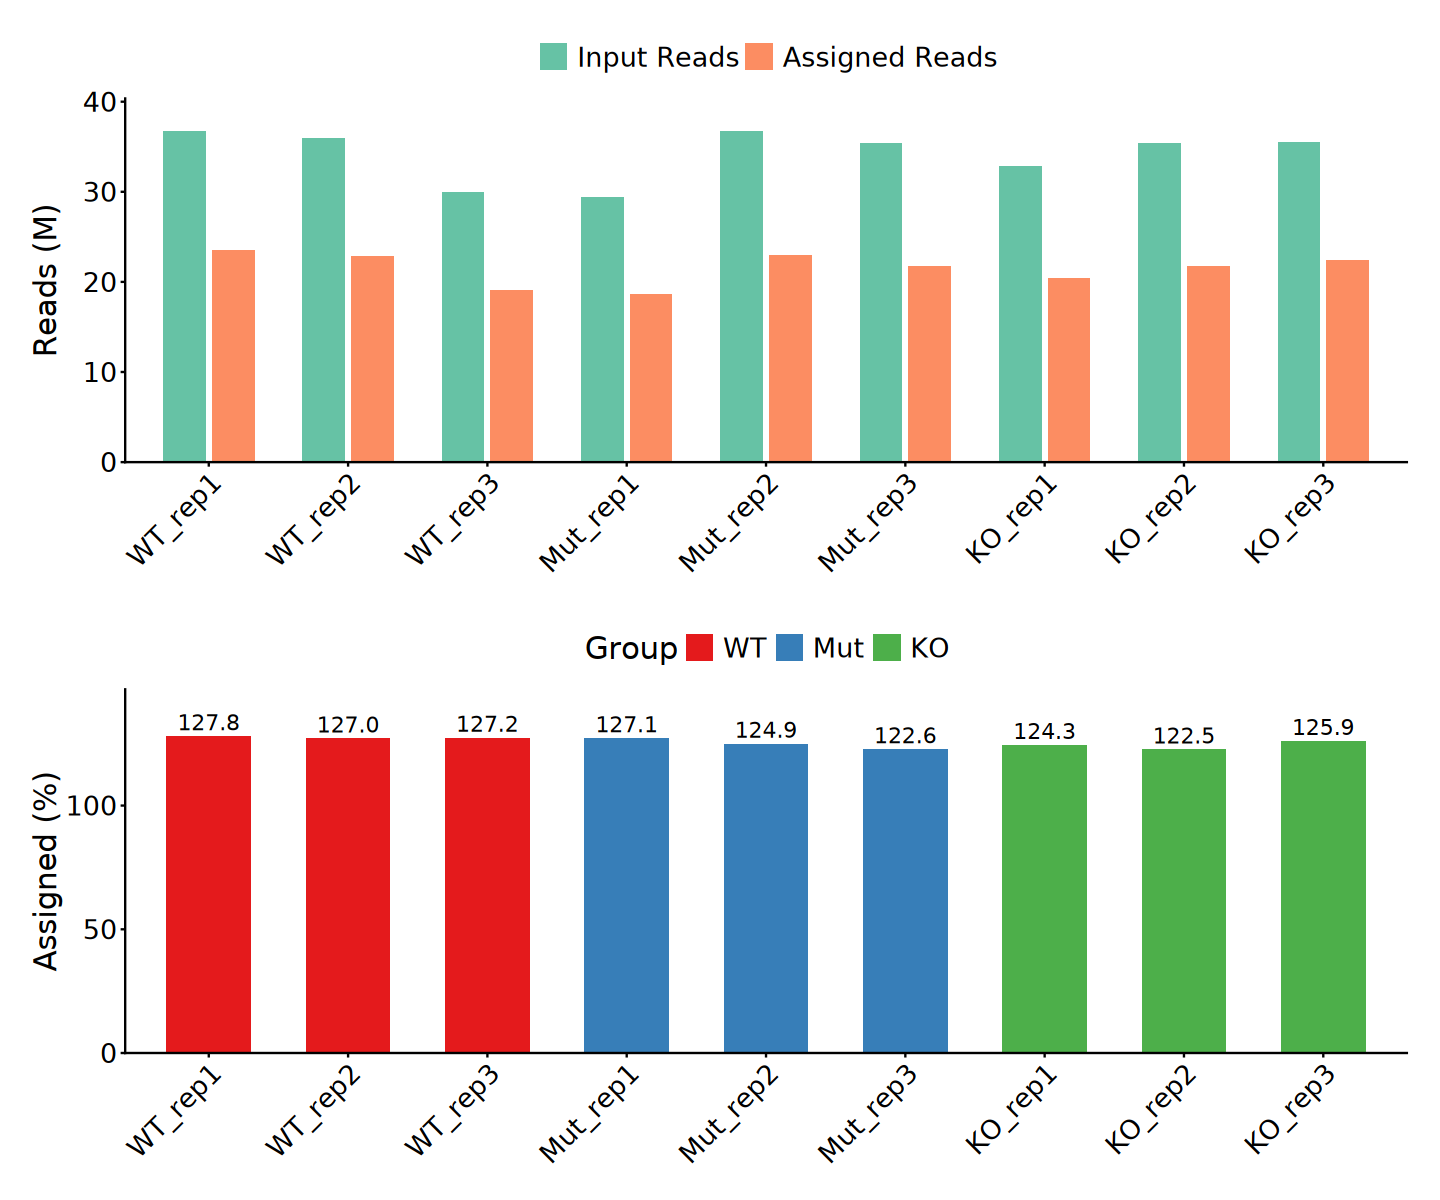

In [17]:
options(repr.plot.width = 12, repr.plot.height = 10)

p1 <- qc_df |>
    pivot_longer(
        cols = c(input_reads, assigned), 
        names_to = "Metric", values_to = "Reads") |>
    mutate(Metric = factor(
        Metric, levels = c("input_reads", "assigned"), 
        labels = c("Input Reads", "Assigned Reads"))) |>
    ggplot(aes(sample, Reads / 1e6, group = Metric)) +
    geom_bar(
        aes(fill = Metric), stat = "identity", 
        position = position_dodge(width = 0.7), width = 0.6) +
    scale_fill_brewer(palette = "Set2") +
    scale_y_continuous(
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    labs(x = NULL, y = "Reads (M)", fill = NULL) +
    qc_theme +
    theme(
        axis.text.x = element_text(angle = 45, hjust = 1), 
        legend.position = "top")

p2 <- ggplot(qc_df, aes(sample, assigned_pct)) +
    geom_bar(aes(fill = Group), stat = "identity", width = 0.6) +
    geom_text(aes(label = sprintf("%.1f", assigned_pct)), 
              vjust = -0.4, size = 4.5) +
    scale_fill_brewer(palette = "Set1") +
    scale_y_continuous(
        limits = c(0, NA), expand = expansion(mult = c(0, 0.15))) +
    labs(x = NULL, y = "Assigned (%)") +
    qc_theme +
    theme(
        axis.text.x = element_text(angle = 45, hjust = 1), 
        legend.position = "top")

p1 / p2 + plot_layout(heights = c(1, 1))

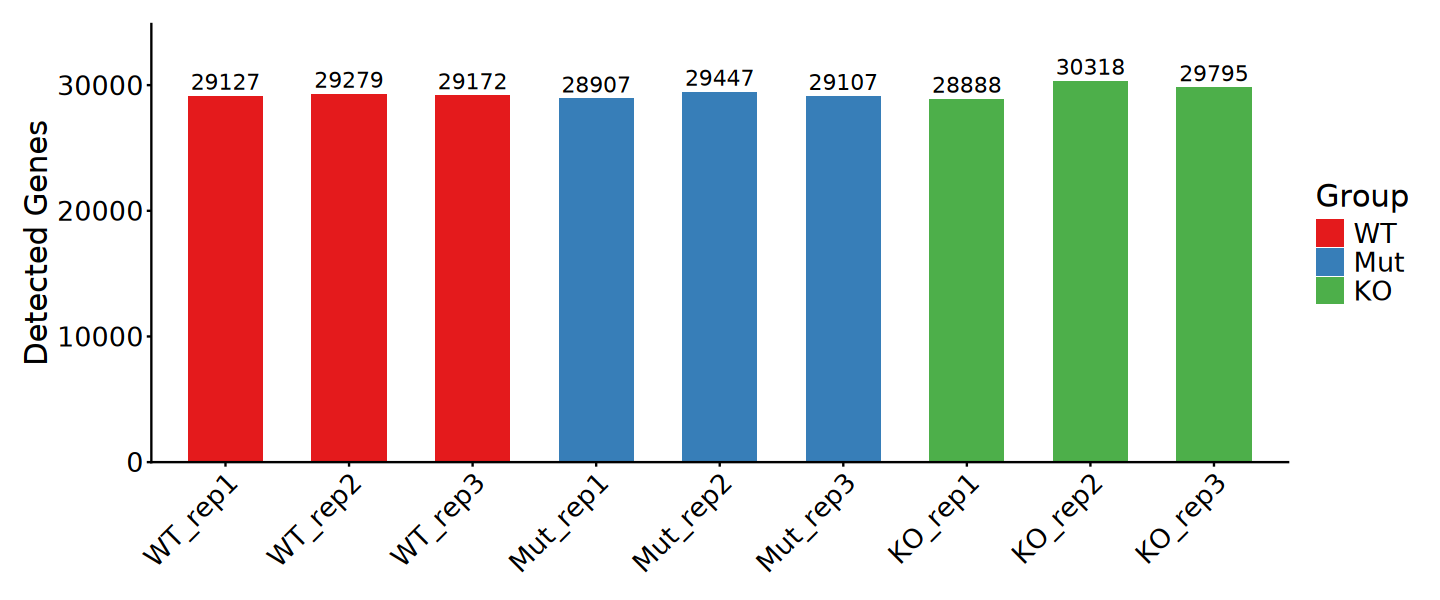

In [18]:
options(repr.plot.width = 12, repr.plot.height = 5)

ggplot(qc_df, aes(sample, detected_genes)) +
    geom_bar(aes(fill = Group), stat = "identity", width = 0.6) +
    geom_text(aes(label = detected_genes), vjust = -0.4, size = 4.5) +
    scale_fill_brewer(palette = "Set1") +
    scale_y_continuous(
        limits = c(0, NA), expand = expansion(mult = c(0, 0.15))) +
    labs(x = NULL, y = "Detected Genes") +
    qc_theme +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

### ERCC Spike-ins

> - ERCC spike-ins were mixed at the same ratio into all samples. Similar ERCC read proportions across libraries confirm spike-in consistency, while differing proportions can flag library preparation bias.

In [19]:
ercc_qc <- tibble(
    sample = colnames(ercc_counts),
    ercc_reads = colSums(ercc_counts),
    ercc_pct = ercc_reads / colSums(counts_mat) * 100, 
    ercc_detected = colSums(ercc_counts > 0))

qc_df <- qc_df |>
    left_join(ercc_qc, by = "sample")

qc_df |>
    dplyr::select(sample, assigned_pct, library_size, 
                  detected_genes, ercc_pct, ercc_detected) |>
    print(n = Inf)

# A tibble: 9 × 6
  sample   assigned_pct library_size detected_genes ercc_pct ercc_detected
  <chr>           <dbl>        <dbl>          <dbl>    <dbl>         <dbl>
1 WT_rep1          128.     23448617          29127    0.383            64
2 WT_rep2          127.     22786840          29279    0.524            71
3 WT_rep3          127.     19008489          29172    0.397            64
4 Mut_rep1         127.     18643619          28907    0.623            72
5 Mut_rep2         125.     22907312          29447    0.612            70
6 Mut_rep3         123.     21678249          29107    0.716            70
7 KO_rep1          124.     20400968          28888    0.705            70
8 KO_rep2          123.     21684719          30318    0.986            70
9 KO_rep3          126.     22353894          29795    0.779            73


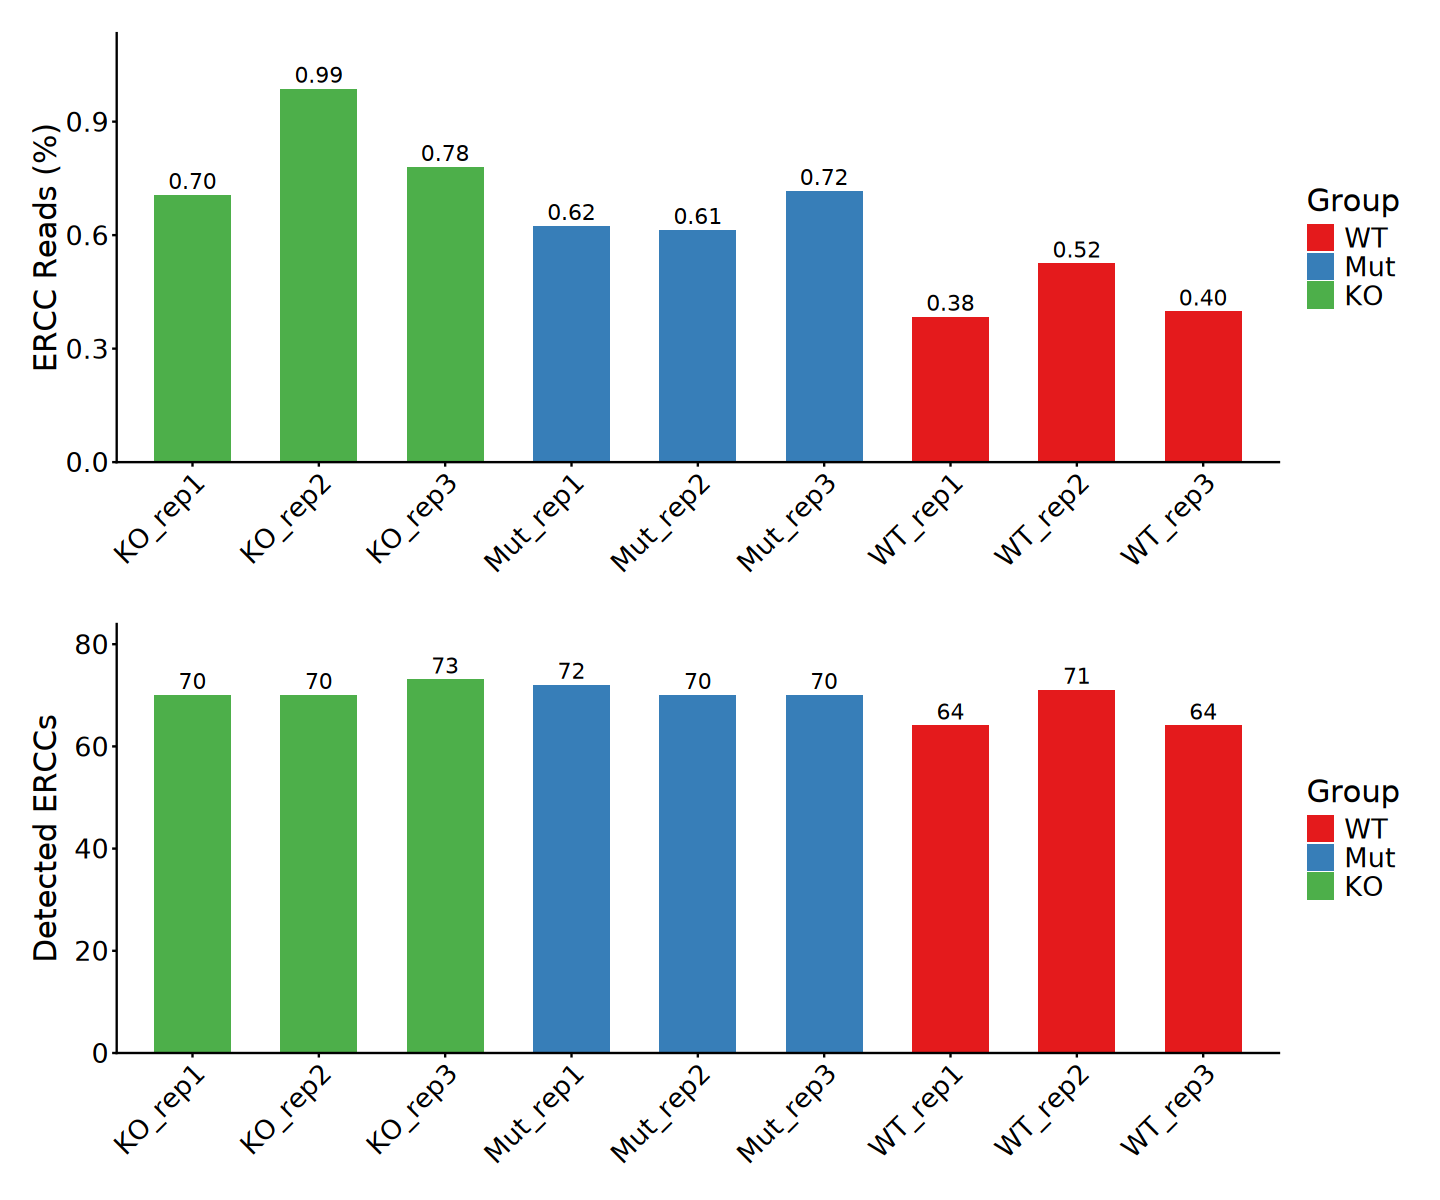

In [20]:
options(repr.plot.width = 12, repr.plot.height = 10)

p1 <- ggplot(qc_df, aes(sample, ercc_pct)) +
    geom_bar(aes(fill = Group), stat = "identity", width = 0.6) +
    geom_text(aes(label = sprintf("%.2f", ercc_pct)), 
              vjust = -0.4, size = 4.5) +
    scale_fill_brewer(palette = "Set1") +
    scale_y_continuous(
        limits = c(0, NA), expand = expansion(mult = c(0, 0.15))) +
    labs(x = NULL, y = "ERCC Reads (%)") +
    qc_theme +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

p2 <- ggplot(qc_df, aes(sample, ercc_detected)) +
    geom_bar(aes(fill = Group), stat = "identity", width = 0.6) +
    geom_text(aes(label = ercc_detected), vjust = -0.4, size = 4.5) +
    scale_fill_brewer(palette = "Set1") +
    scale_y_continuous(
        limits = c(0, NA), expand = expansion(mult = c(0, 0.15))) +
    labs(x = NULL, y = "Detected ERCCs") +
    qc_theme +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

p1 / p2 + plot_layout(heights = c(1, 1))

### Genotype Sanity Check

> - Tet1 transcript should be abundant in WT, retained in the catalytically-dead Mut (the Tet1 locus is intact), and near-absent in KO. This confirms sample genotype and group assignment before downstream analysis.

In [21]:
tet1_ids <- rownames(anno_gene)[which(anno_gene$symbol == "Tet1")]

cat("Tet1 gene(s):\n")
print(anno_gene[tet1_ids, , drop = FALSE])

Tet1 gene(s):
DataFrame with 1 row and 3 columns
                           symbol           type basepairs
                      <character>    <character> <integer>
ENSMUSG00000047146.17        Tet1 protein_coding     15457


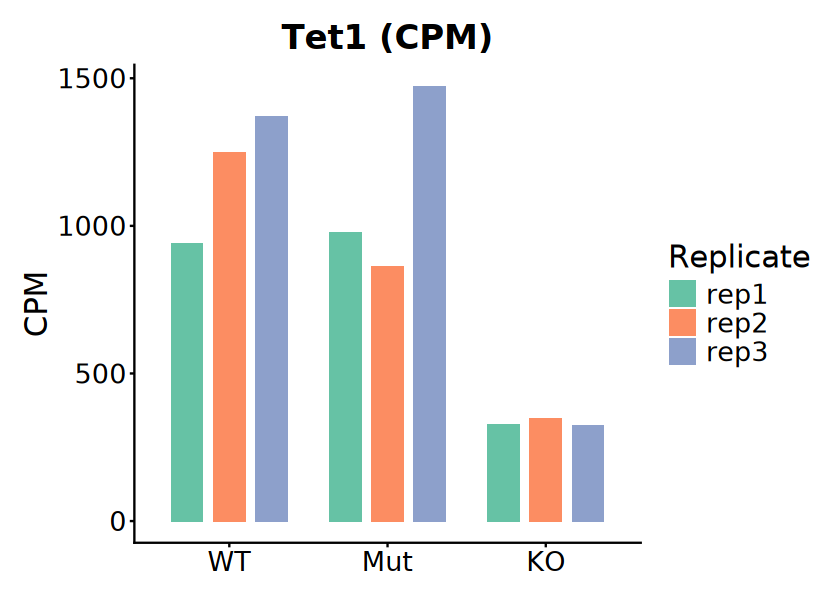

In [22]:
options(repr.plot.width = 7, repr.plot.height = 5)

tet1_df <- counts_mat[tet1_ids, , drop = FALSE] |>
    (\(x) sweep(x, 2, colSums(counts_mat), FUN = "/") * 1e6)() |>
    as.data.frame() |>
    rownames_to_column("gene_id") |>
    pivot_longer(-gene_id, names_to = "sample", values_to = "cpm") |>
    left_join(
        coldata |> as.data.frame() |> rownames_to_column("sample"), 
        by = "sample")

ggplot(tet1_df, aes(Group, cpm)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), width = 0.6) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Tet1 (CPM)", x = NULL, y = "CPM") +
    qc_theme

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [23]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18863 
 Remove: 36472 
 Retention rate: 34.09 %


In [24]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18748 
 Remove: 36587 
 Retention rate: 33.88 %


# 3. Normalization

In [25]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [26]:
vsd <- vst(dds, blind = FALSE)

In [27]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [28]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [29]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [30]:
suppressPackageStartupMessages(library(vsn))

In [31]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [32]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


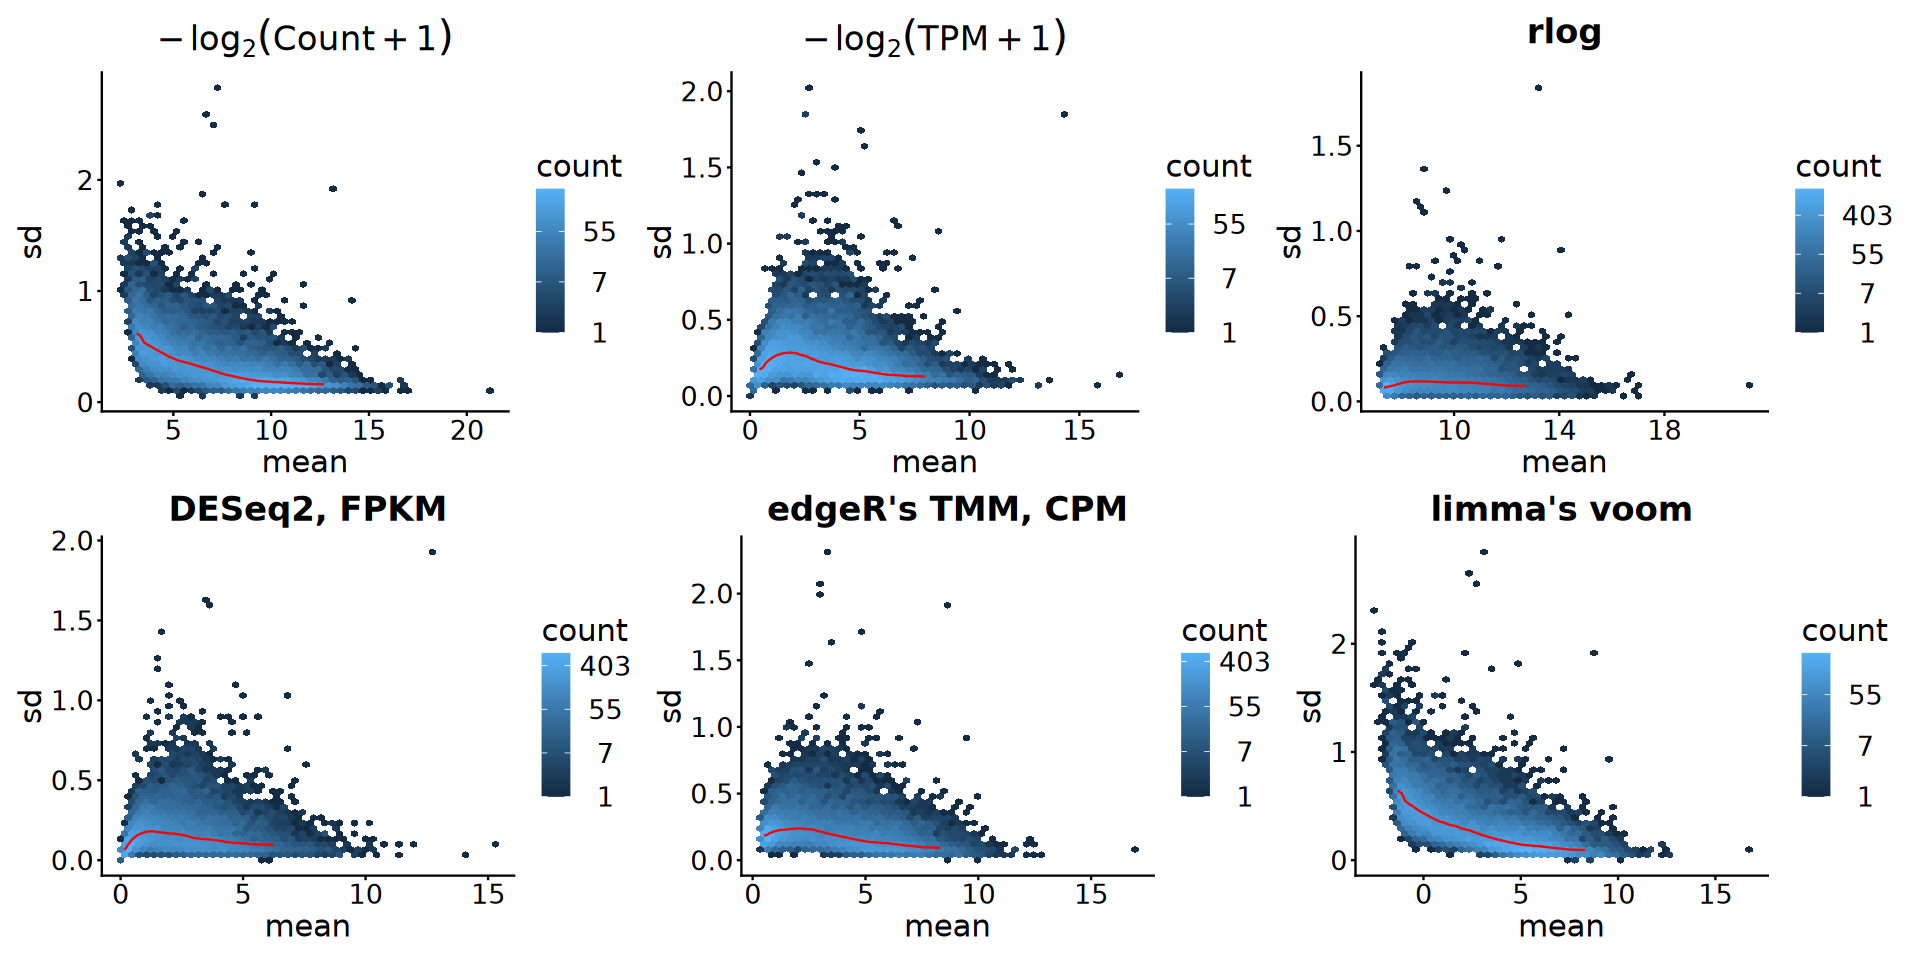

In [33]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [34]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(vsd)

### 1). Overview

In [35]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

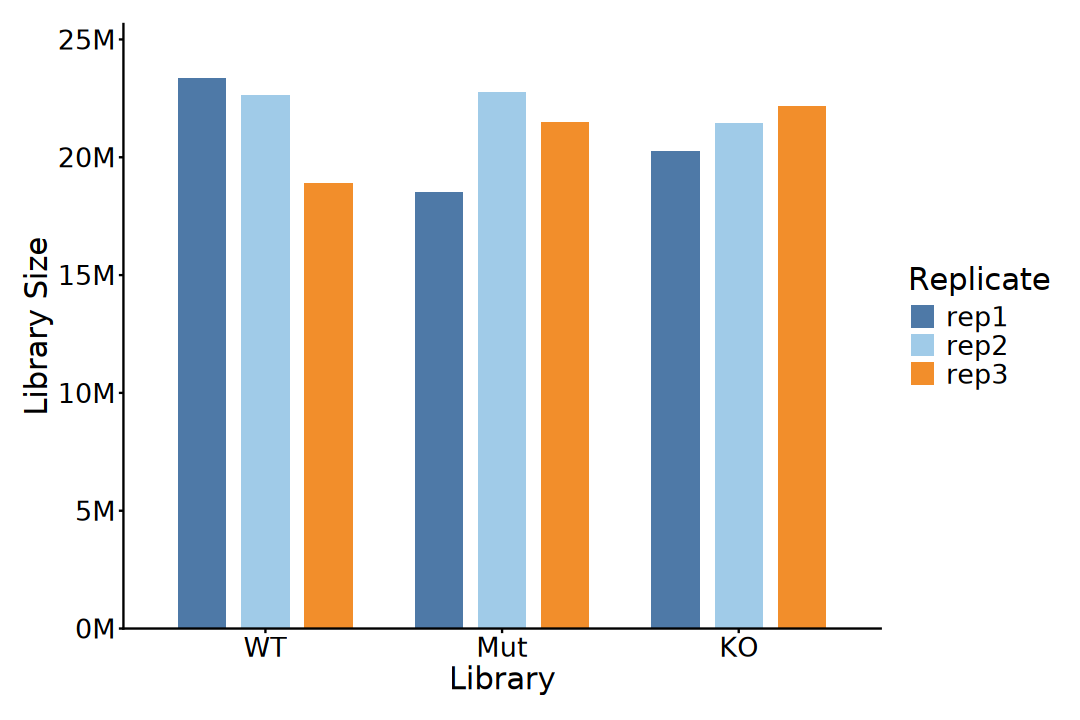

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    ggthemes::scale_color_tableau(palette = "Tableau 20") + 
    ggthemes::scale_fill_tableau(palette = "Tableau 20") + 
    labs(x = "Library", y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [37]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [38]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [39]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
pca_res <- plotPCA(
    vsd, intgroup = c("Group", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [41]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [42]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [43]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

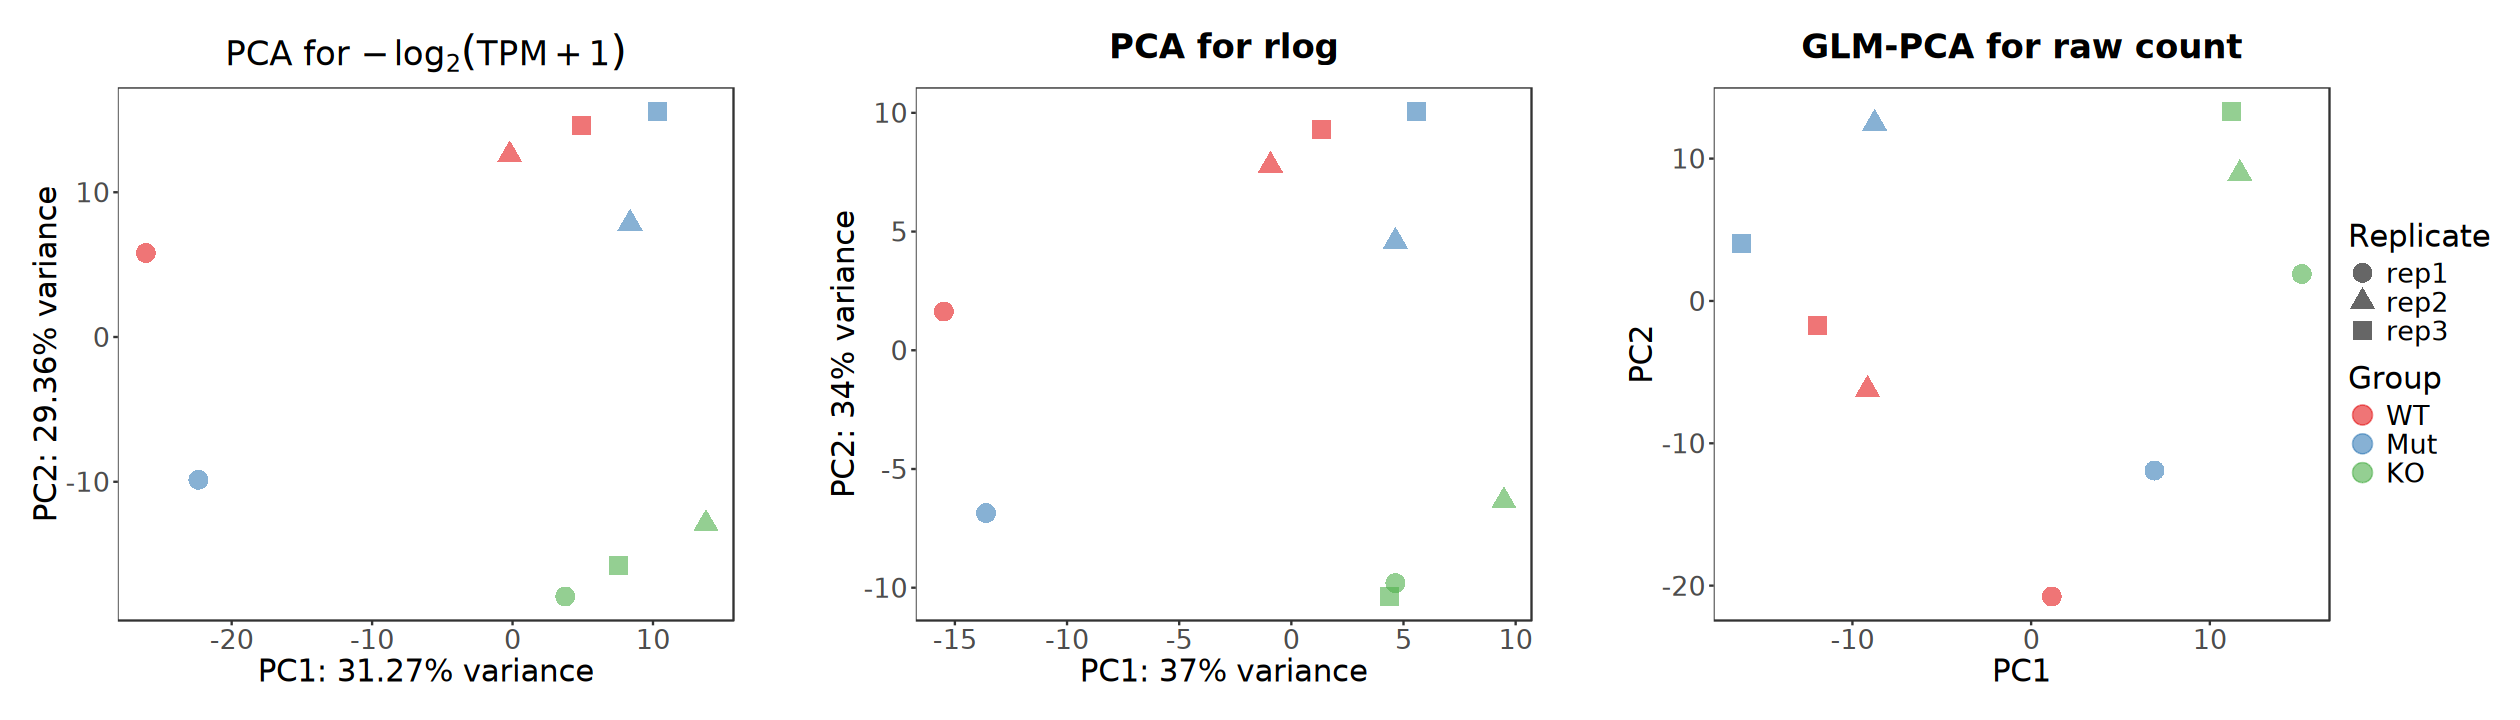

In [44]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [45]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

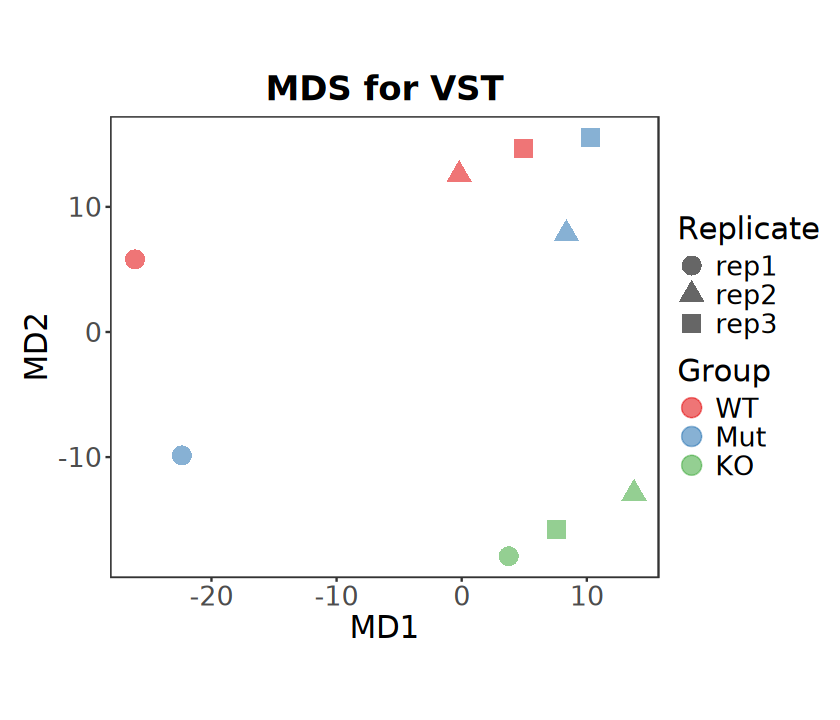

In [46]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    ggtitle("MDS for VST") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [47]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

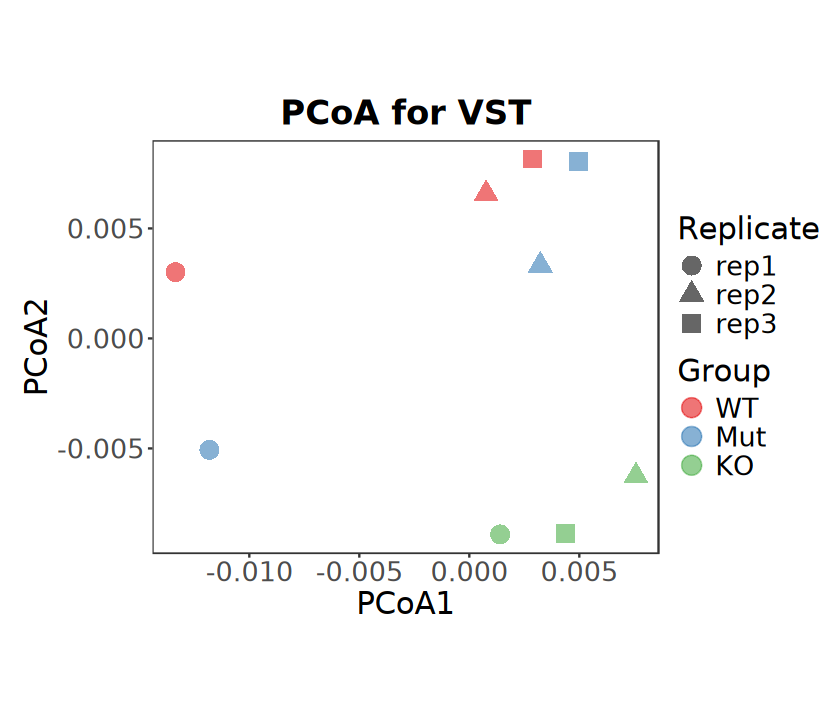

In [48]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    ggtitle("PCoA for VST") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [49]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Group, Replicate)

In [50]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(Group = group_colors, Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [51]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

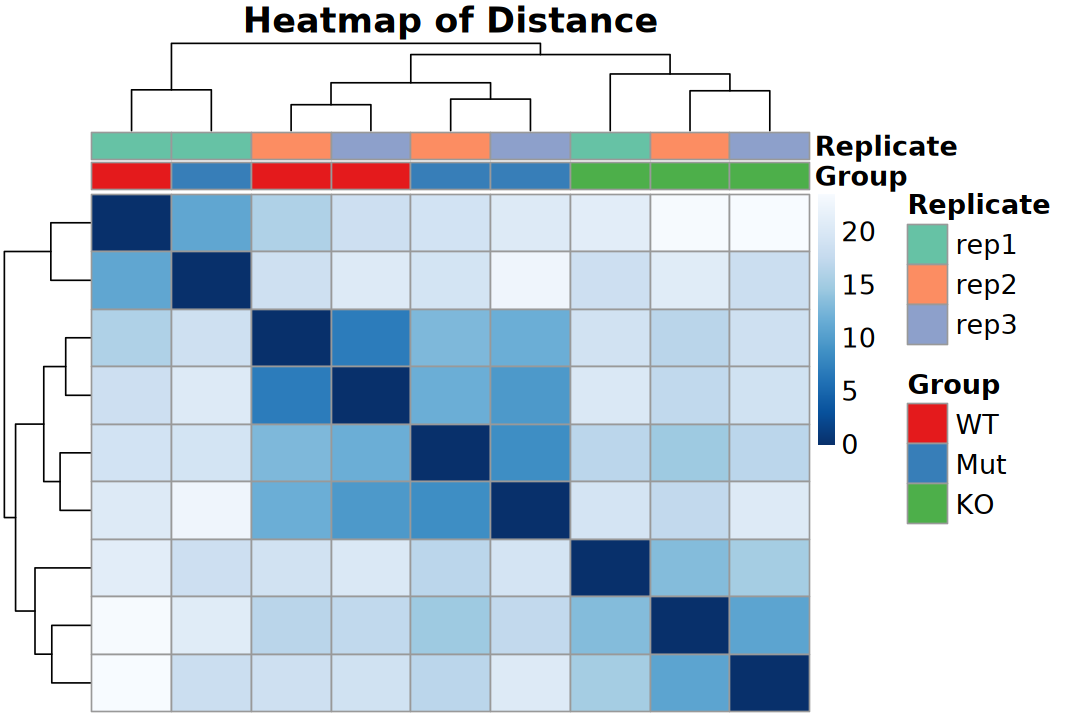

In [52]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [53]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

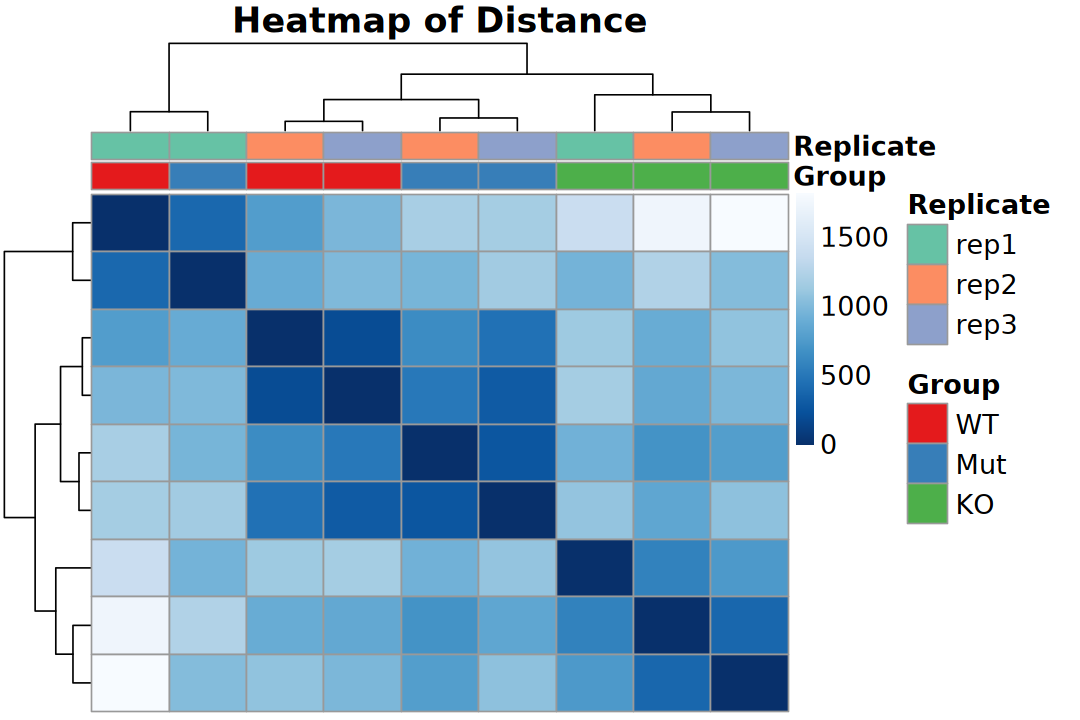

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [55]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

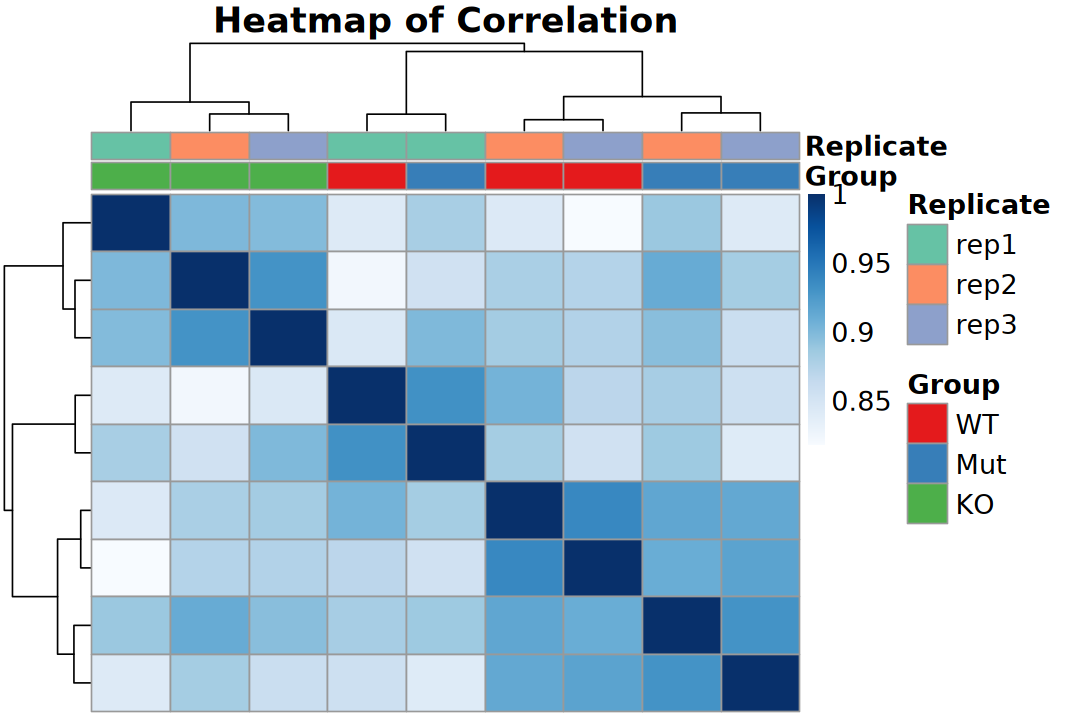

In [56]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

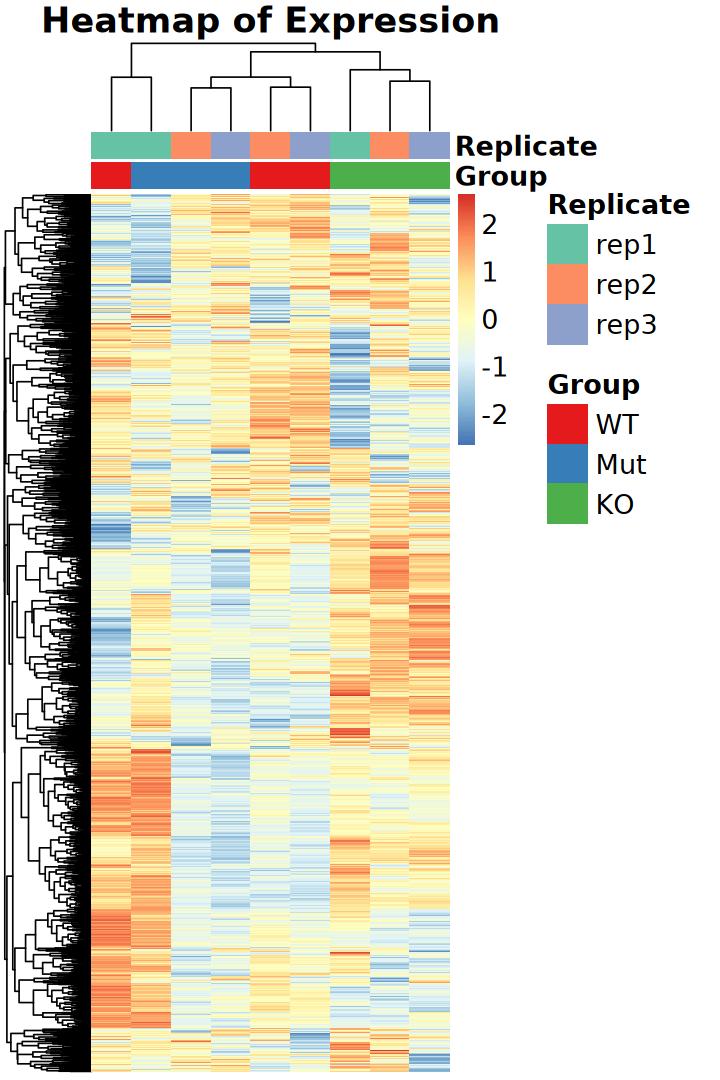

In [57]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [58]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [59]:
design(dds) <- ~ 0 + Group
design(dds)

~0 + Group

In [60]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [61]:
resultsNames(dds)

[1] "GroupWT"  "GroupMut" "GroupKO"

In [62]:
contrast_pairs <- levels(dds$Group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

[[1]]
[1] "WT"  "Mut"

[[2]]
[1] "WT" "KO"

[[3]]
[1] "Mut" "KO"

[1] "Mut_vs_WT" "KO_vs_WT"  "KO_vs_Mut"

### a). Standard

In [63]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Group", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [64]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

           
               Up  Down    NS
  Mut_vs_WT     0     1 18862
  KO_vs_WT      8    21 18834
  KO_vs_Mut     1     1 18861

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.
>
> Notes:
> - `apeglm` shrunken LFC requires specific coefficients from resultsNames(dds). Re-leveling the reference group is necessary to compute contrasts not inherently present in the initial design matrix.

In [65]:
deseq2_lfc_result_list <- map(contrast_pairs, function(lv) {
    lfcShrink(dds, contrast = c("Group", lv[2], lv[1]), type = "ashr") |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2-lfcShrink",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041



In [66]:
deseq2_lfc_result_df <- bind_rows(deseq2_lfc_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_lfc_result_df$contrast, deseq2_lfc_result_df$result)

           
               Up  Down    NS
  Mut_vs_WT     0     1 18862
  KO_vs_WT      0     2 18861
  KO_vs_Mut     0     0 18863

In [67]:
comparison_df <- deseq2_result_df |> 
    dplyr::select(gene_id, contrast, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result_df |> 
            dplyr::select(gene_id, contrast, result_lfc = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(Raw = sub_df$result_raw, LFC_Shrink = sub_df$result_lfc))
    })


Contrast: Mut_vs_WT 
      LFC_Shrink
Raw       Up  Down    NS
  Up       0     0     0
  Down     0     1     0
  NS       0     0 18862

Contrast: KO_vs_WT 
      LFC_Shrink
Raw       Up  Down    NS
  Up       0     0     8
  Down     0     2    19
  NS       0     0 18834

Contrast: KO_vs_Mut 
      LFC_Shrink
Raw       Up  Down    NS
  Up       0     0     1
  Down     0     0     1
  NS       0     0 18861


In [68]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

           
               Up  Down    NS
  Mut_vs_WT     0     1 18862
  KO_vs_WT      8    21 18834
  KO_vs_Mut     1     1 18861

In [69]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### Multi-group Volcano

In [70]:
p1 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

In [71]:
p2 <- ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = logFC, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), width = 0.9,
        height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast),
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_gradientn(
        name = "logFC",
        colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25"), 
        limits = c(-max_logfc, max_logfc)) +
    # scale_color_viridis_c(
    #     name = "logFC", option = "turbo", begin = 0.1, end = 0.9, 
    #     limits = c(-max_logfc, max_logfc)) + 
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

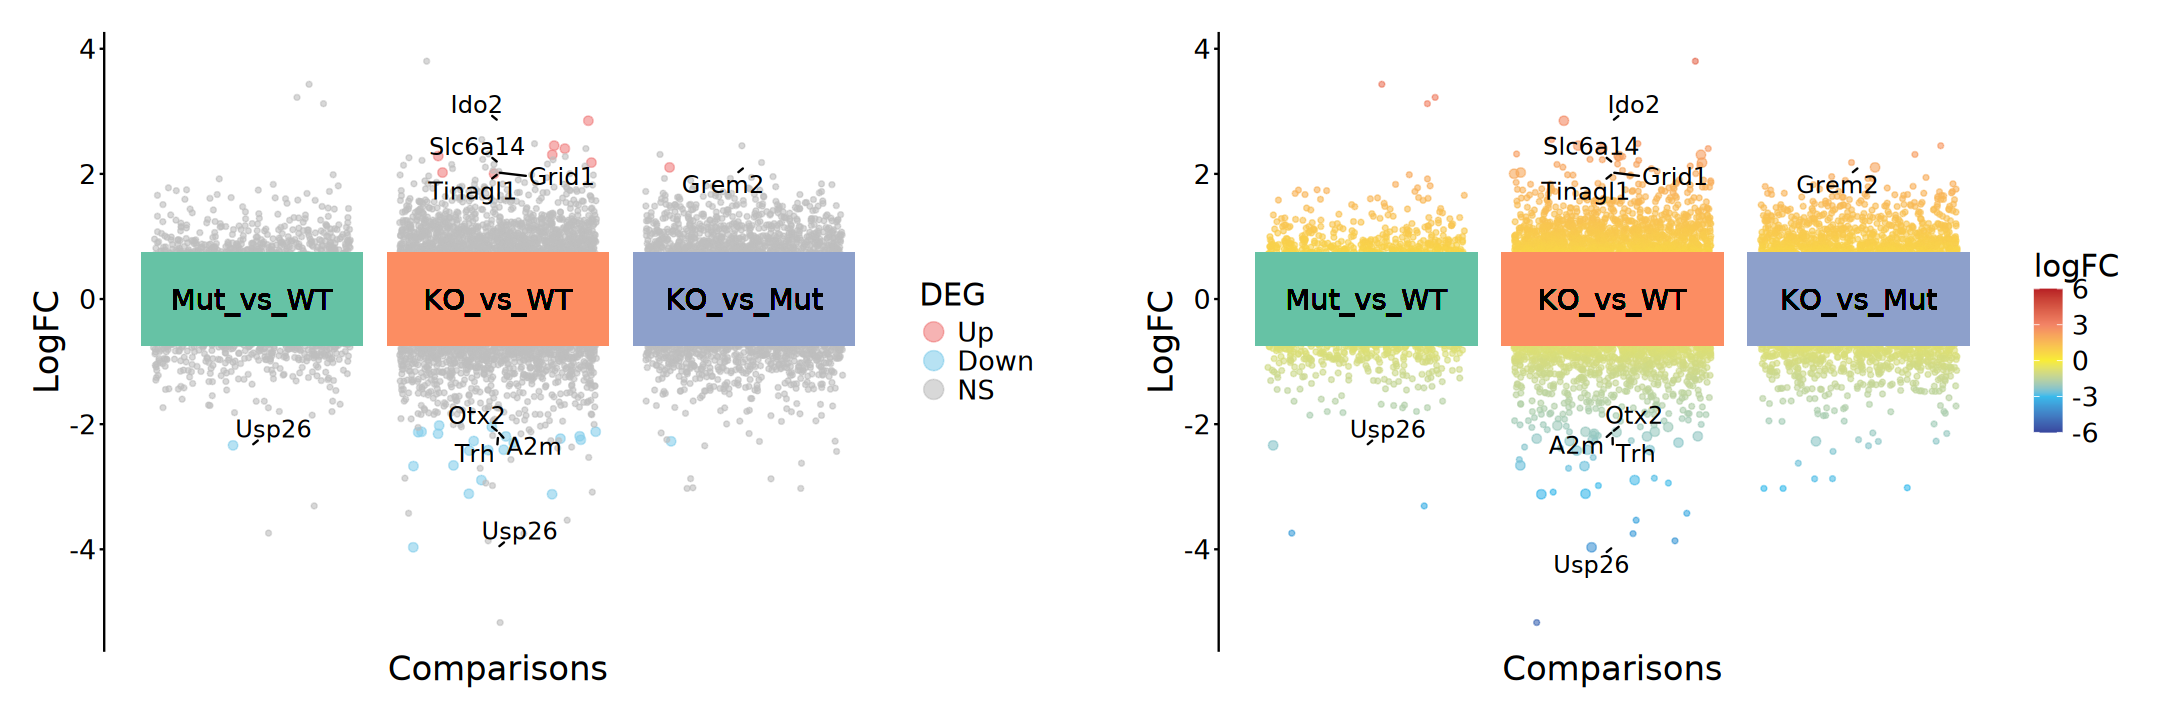

In [72]:
options(repr.plot.width = 18, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Bubble Matrix Plot

In [73]:
top_genes <- deg_df |> filter(result != "NS") |> 
    group_by(contrast) |> 
    slice_min(order_by = padj, n = 5) |> 
    slice_max(order_by = abs(logFC), n = 5) |> 
    pull(gene_id) |> unique()

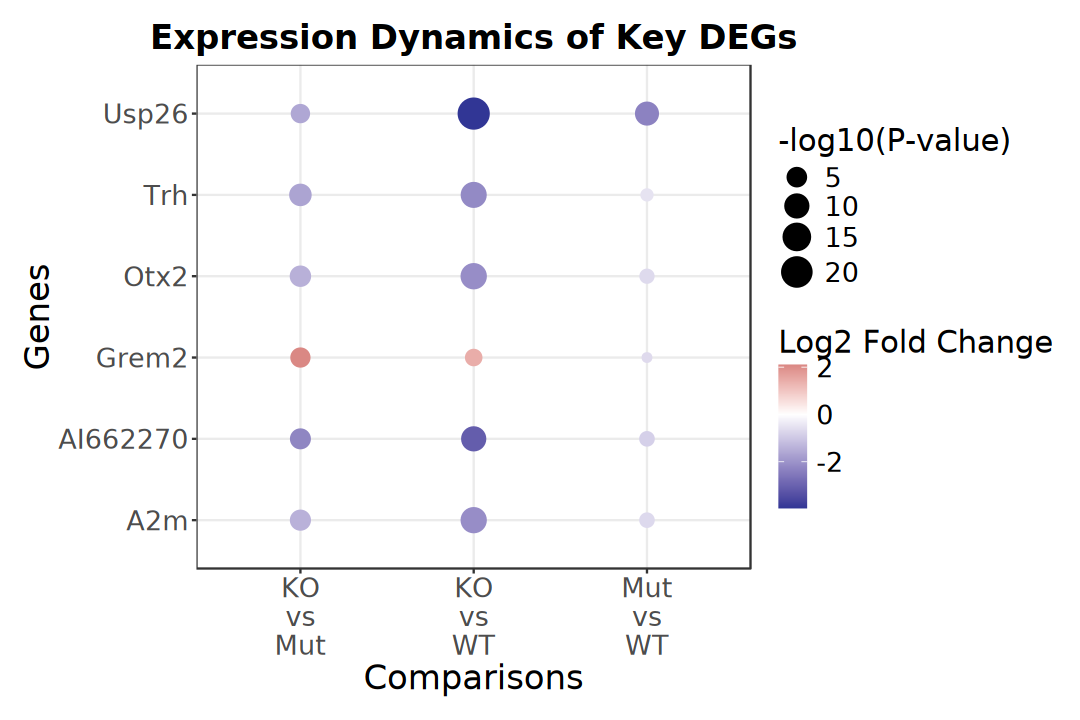

In [74]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_df |> filter(gene_id %in% top_genes) |> 
    mutate(
        Group = str_replace_all(contrast, "_", "\n"),
        neg_log10P = -log10(pvalue)) |> 
    ggplot(aes(x = Group, y = symbol, size = neg_log10P, color = logFC)) +
    geom_point() +
    scale_color_gradient2(
        low = "#313695", mid = "white", high = "#a50026", 
        midpoint = 0) +
    scale_size_continuous(range = c(2, 8)) +
    labs(
        title = "Expression Dynamics of Key DEGs",
        x = "Comparisons", y = "Genes",
        color = "Log2 Fold Change", size = "-log10(P-value)") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16))

### Heatmap

In [75]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [76]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))


ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group)

In [77]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels) |>
    append(list(Group = group_colors))

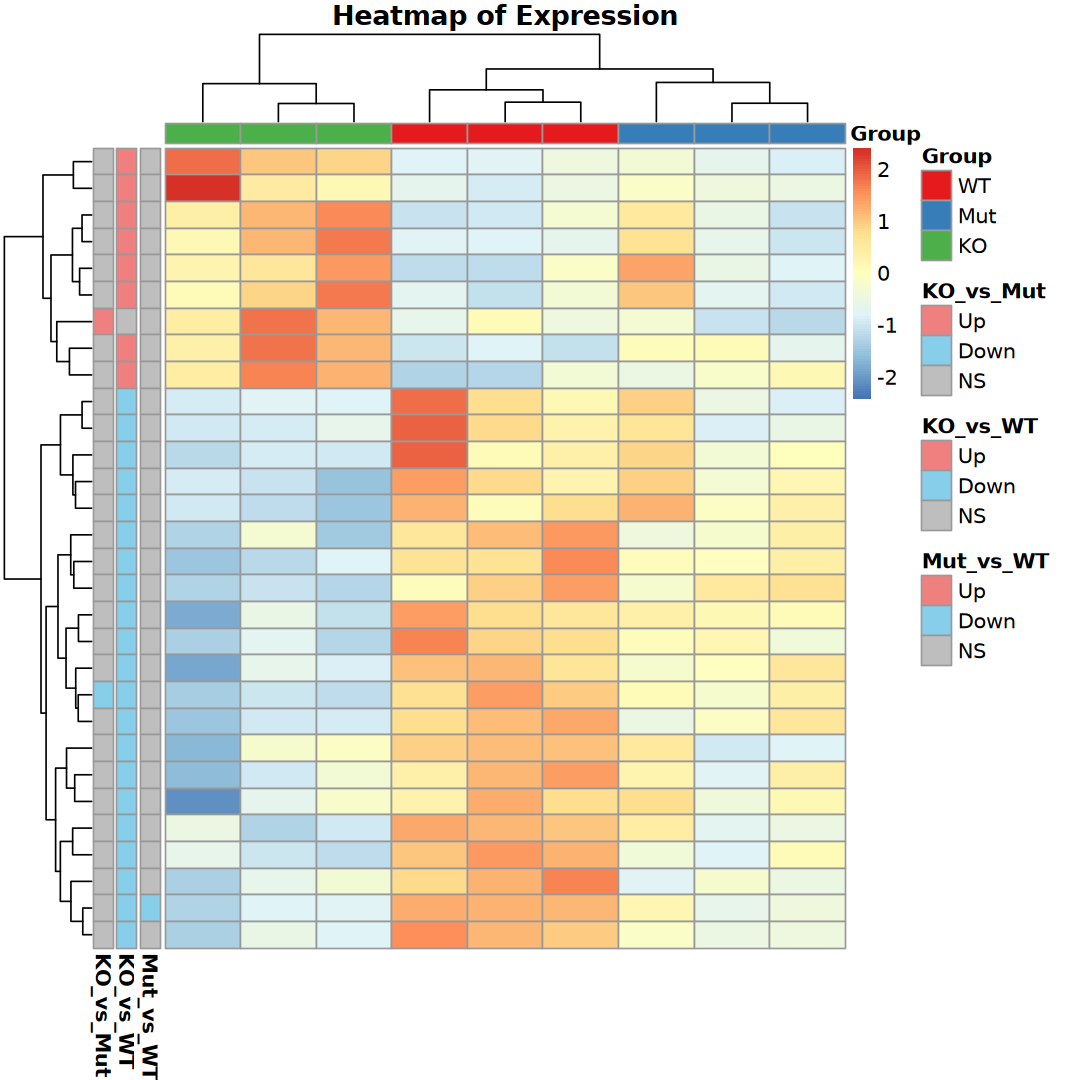

In [78]:
options(repr.plot.width = 9, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [79]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [80]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [81]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [82]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(Group = group_colors))

In [83]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [84]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [85]:
lg_heatmap <- Legend(title = "Expression (z-score)",
                     col_fun = heatmap_col)

lg_group <- Legend(title = "Group", 
                   labels = levels(dds$Group))

lg_deg <- Legend(labels = levels(deg_df$result), title = "DEG", 
                 legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group) |>
    packLegend(direction = "vertical")

In [86]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(name = "Expression", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno, 
            right_annotation = right_anno,
            show_row_names = FALSE, 
            show_column_names = FALSE, 
            use_raster = TRUE)

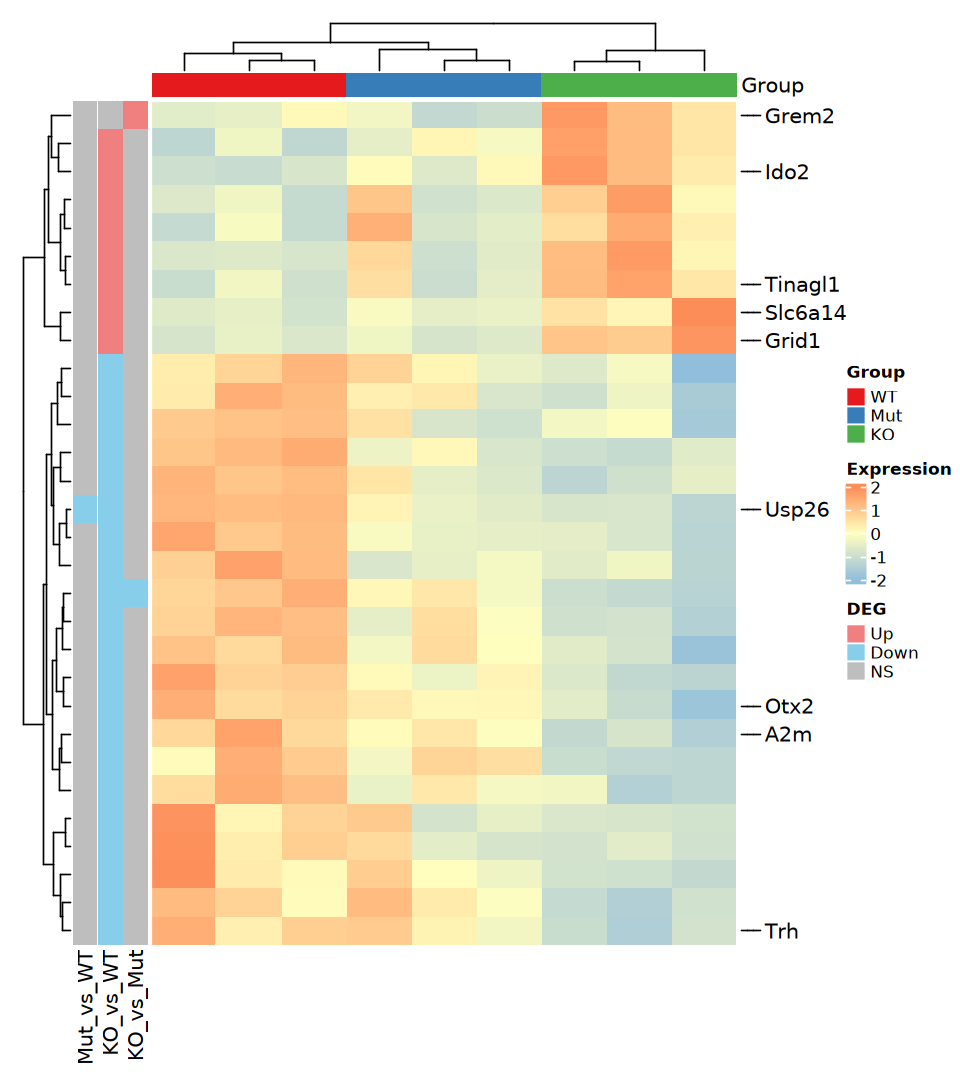

In [87]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(ht + combined_leg, merge_legend = TRUE,
     annotation_legend_list = list(lg_deg), 
     legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
     legend_labels_gp = gpar(fontsize = 10), 
     padding = unit(c(5, 5, 5, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [88]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [89]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [90]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

           
               Up  Down    NS
  Mut_vs_WT     0     1 18862
  KO_vs_WT      8    21 18834
  KO_vs_Mut     1     1 18861

In [91]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“17.59% of input gene IDs are fail to map...”


In [92]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [93]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [94]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,KO_vs_WT_Up,BP,GO:0010172,embryonic body morphogenesis,1/1,10/14118,0.10000000,1411.8000,37.56062,0.0007083156,0.005902630,NA,1
2,KO_vs_WT_Up,BP,GO:1900115,extracellular regulation of signal transduction,1/1,10/14118,0.10000000,1411.8000,37.56062,0.0007083156,0.005902630,NA,1
3,KO_vs_WT_Up,BP,GO:1900116,extracellular negative regulation of signal transduction,1/1,10/14118,0.10000000,1411.8000,37.56062,0.0007083156,0.005902630,NA,1
4,KO_vs_WT_Up,BP,GO:0043393,regulation of protein binding,1/1,14/14118,0.07142857,1008.4286,31.74002,0.0009916419,0.006197762,NA,1
5,KO_vs_WT_Up,BP,GO:0010469,regulation of signaling receptor activity,1/1,21/14118,0.04761905,672.2857,25.90918,0.0014874628,0.007437314,NA,1
6,KO_vs_WT_Up,MF,GO:0036122,BMP binding,1/1,14/13925,0.07142857,994.6429,31.52210,0.0010053860,0.009048474,NA,1


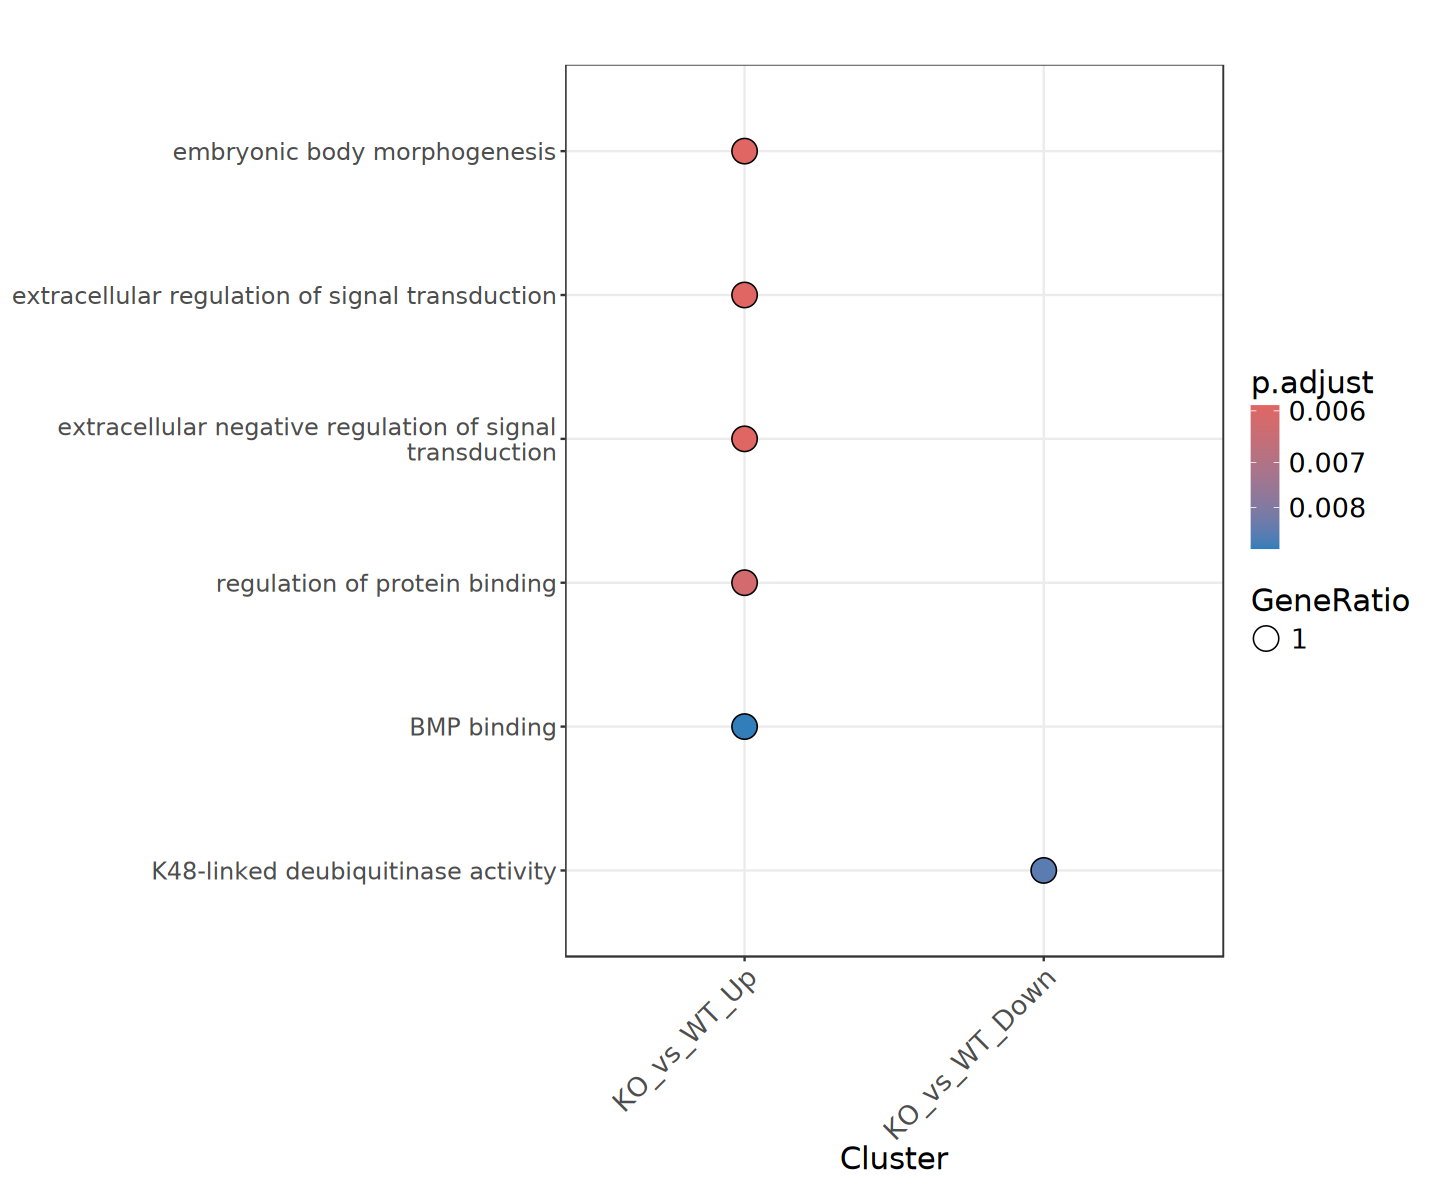

In [95]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [96]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    map(unique)

In [97]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in file(file, "rt"):
“URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached”
Warning message in compareCluster(geneCluster = genes_list, fun = enrichKEGG, universe = unique(deg_df$ENTREZID), :
“No enrichment found in any of gene cluster, please check your input...”


In [98]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

ERROR: Error in h(simpleError(msg, call)): error in evaluating the argument 'x' in selecting a method for function 'head': no applicable method for 'select' applied to an object of class "NULL"


In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)